In [1]:
%cd ../

# Import required libraries 
from pathlib import Path
import hydra
from omegaconf import DictConfig, OmegaConf, open_dict
import torch
from lightning import seed_everything
import matplotlib.pyplot as plt

from modules.loader.loaders import trainScaler
#from cel.CE import ECLAD
from cel.utils.layers import getLayers, compute_RF_numerical
from cel.utils.reporting import sorted_inputs, sorted_inputs_regression,plot_concepts_report_from_HF
from cel.utils.maskgen import extract_ConceptMasks
from datasets import Dataset


plt.rcParams.update({
    "text.usetex": True,
    "font.family": 'serif',
    'font.serif': ['computer modern roman'],
    'font.size': 20
})

d:\DSME\Code\Repos\CEL


d:\DSME\Code\Repos\CEL\.venv\lib\site-packages\IPython\core\magics\osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [2]:
#@hydra.main(config_path="../data/config", config_name="train_model", version_base="1.3")
hydra.initialize(version_base=None, config_path="../data/config", job_name="test_app")

hydra.initialize()

In [3]:
cfg = hydra.compose(config_name="train_CE.yaml", overrides=["training=adamw_patient", "path=applewood_local","model=ResNet1D18", "dataset=SPP5_shear_TC", 
                                                            "path=applewood_local", "transforms=tsHFNoise", "loader=M",
                                                            "seed=0", "CE=ECLADts", "CE.n_concepts=10","CE.loader.batch_size=20","CE.n_instances=100"])

In [4]:
##############################
# Preliminaries
##############################
save_dir = Path(cfg.save_dir_model)

# Set the random seed for reproducibility
seed_everything(cfg.seed)
#torch.set_flush_denormal(True) # To avoid significant performance drop on CPU when the numbers get close to 0 (like 10e-324)

# Select the device for computation (CUDA, MPS, or CPU)
device = "cuda" if (cfg.training.device=="cuda" and torch.cuda.is_available()) else "cpu"
# device='cpu'
# Train scaler if necessary
if cfg.transforms.standardize:
    cfg.dataset.mean, cfg.dataset.std = trainScaler(cfg.dataset, cfg.loader)

Seed set to 0


In [5]:
# Instantiate transforms for training and testing
pretransform = hydra.utils.instantiate(cfg.dataset.pretransform)
train_transform = hydra.utils.instantiate(cfg.transforms.train)
valid_transform = hydra.utils.instantiate(cfg.transforms.val)
test_transform = hydra.utils.instantiate(cfg.transforms.test)

# Instantiate datasets with transforms
train_dataset = hydra.utils.instantiate(cfg.dataset.train, transform=train_transform, pretransform=pretransform, withId = True)
valid_dataset = hydra.utils.instantiate(cfg.dataset.val, transform=valid_transform, pretransform=pretransform, withId = True)
test_dataset = hydra.utils.instantiate(cfg.dataset.test, transform=test_transform, pretransform=pretransform, withId = True)

# Instantiate data loaders
# train_loader = hydra.utils.instantiate(cfg.loader.train, dataset=train_dataset)
# valid_loader = hydra.utils.instantiate(cfg.loader.val, dataset=valid_dataset)
# test_loader = hydra.utils.instantiate(cfg.loader.test, dataset=test_dataset)
train_loader, valid_loader, test_loader =  hydra.utils.instantiate(cfg.CE.loader, dataset_train=train_dataset, dataset_val=valid_dataset, dataset_test=test_dataset, task=cfg.dataset.task) 

In [6]:
valid_loader.pin_memory=True

In [7]:
# Instantiate model
model = hydra.utils.instantiate(cfg.model.object) #.to(device)
PATH=f'{save_dir}/best.pth'
model.load_state_dict(torch.load(PATH, weights_only=True))
getLayers(model) #, model.named_children
model.eval()

ResNet(
  (conv1): Conv1d(14, 64, kernel_size=(3,), stride=(1,), padding=(1,), bias=False)
  (bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (layers): ModuleList(
    (0): Sequential(
      (0): ResidualBlock(
        (conv1): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,), bias=False)
        (bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,), bias=False)
        (bn2): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
      )
      (1): ResidualBlock(
        (conv1): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,), bias=False)
        (bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (co

In [8]:
# Instantiate CE object
CE=hydra.utils.instantiate(cfg.CE.object, model=model)

In [9]:
# Fit CE object if it has not alerady been fit
# cfg.mode='force' # comment out
fitExists, reportExists = CE.check_existence(cfg.CE)
if cfg.mode == "force" or not fitExists:
    print("training Explainer")
    CE.fit(train_loader, cfg.CE, device=device)
    CE.save(cfg.CE)
    # Save the configuration
    with open(f"{cfg.CE.save_dir}/config.yaml", "w") as f:
        OmegaConf.save(config=cfg, f=f)
else:
    CE.load(cfg.CE, device=device)
    print("loaded Explainer from files")

loaded Explainer from files


In [10]:
#CE.centroids.shape, CE.n_concepts, CE.importances

In [11]:
# batchx, batchy,batchid = next(iter(valid_loader))
# ma = CE.eval(batchx)
if cfg.CE.name == 'ConceptShap':
    c_indexes = [int(k) for k, _ in sorted(CE.importances.items(), key=lambda item: item[1], reverse=True)]
else:
    c_indexes=None

In [12]:
# # Make CE report if it does not exist already
# # cfg.CE.decorrelated=True
# # cfg.CE.domain='input'
# cfg.mode='force-report'
# if  cfg.mode == "force" or cfg.mode == "force-report" or not reportExists:
#     if cfg.dataset.task == "classification":
#         batch = sorted_inputs(
#             CE.model, valid_loader, n_classes=cfg.dataset.n_classes, n_repeats=2
#         )
#     elif cfg.dataset.task == "regression":
#         batch = sorted_inputs_regression(
#             valid_loader, partitions=5,samples_per_partition=1, int_out=cfg.CE.multilabel_out, astensor=True
#         )
#     else:
#         batch = next(iter(valid_loader))

#     if isinstance(batch, dict):
#         test_inputs, test_truth = batch["x"][:4], batch["y"][:4]
#     else:
#         test_inputs, test_truth, _ = batch[:4]

#     for domain in cfg.CE.domain:
#         print(f'Plotting report on {domain} domain')
#         test_masks, test_outputs = CE.eval(test_inputs,domain=domain, device=device) 
#         # c_indexes=[int(k) for k, v in sorted(EC.importances.items(), key=lambda item: item[1],reverse=True)]

#         CE.report(
#             test_masks,
#             cfg.CE,
#             test_inputs,
#             test_outputs,
#             domain=domain,
#             test_truth=test_truth,
#             c_indexes=c_indexes,
#             DS_cfg=cfg.dataset,
#             font_base = 5
#         ) 

#         plt.show()

In [13]:
# if 'fourier' in cfg.CE.domain:
#     cc=CE.concept_correspondence(valid_loader, num_batches=20, device=device)
#     CE.plot_CC(cc,cfg.CE, fs=1)

In [ ]:
samples_x, samples_y, samples_id = sorted_inputs_regression(train_loader,samples_per_partition=10, partitions=6,int_out=0, DS_cfg=cfg.dataset, astensor=False)

d:\DSME\Code\Repos\CEL\cel\utils\reporting.py:95: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen/native/BucketizationUtils.h:34.)
  bin_idx = torch.bucketize(y_scalar, bnd)  # values in [0, partitions-1]


In [15]:
extract_ConceptMasks(CE, samples_x, samples_y, samples_id, cfg.dataset, modelname=cfg.name)

Saving the dataset (0/1 shards):   0%|          | 0/10 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/10 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/10 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/10 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/10 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/10 [00:00<?, ? examples/s]

In [16]:
outdir = 'D:/Datasets/DS_TS/WZL/SPP/ConceptMasks'
modelname = cfg.name
bucket=str(0)
d1 = Dataset.load_from_disk(f"{outdir}/{modelname}/bin{bucket}_masks")

report saved at: D:/Datasets/DS_TS/WZL/SPP/ConceptMasks\concepts.png


('D:/Datasets/DS_TS/WZL/SPP/ConceptMasks\\concepts.png',
 'D:/Datasets/DS_TS/WZL/SPP/ConceptMasks\\concepts.pdf')

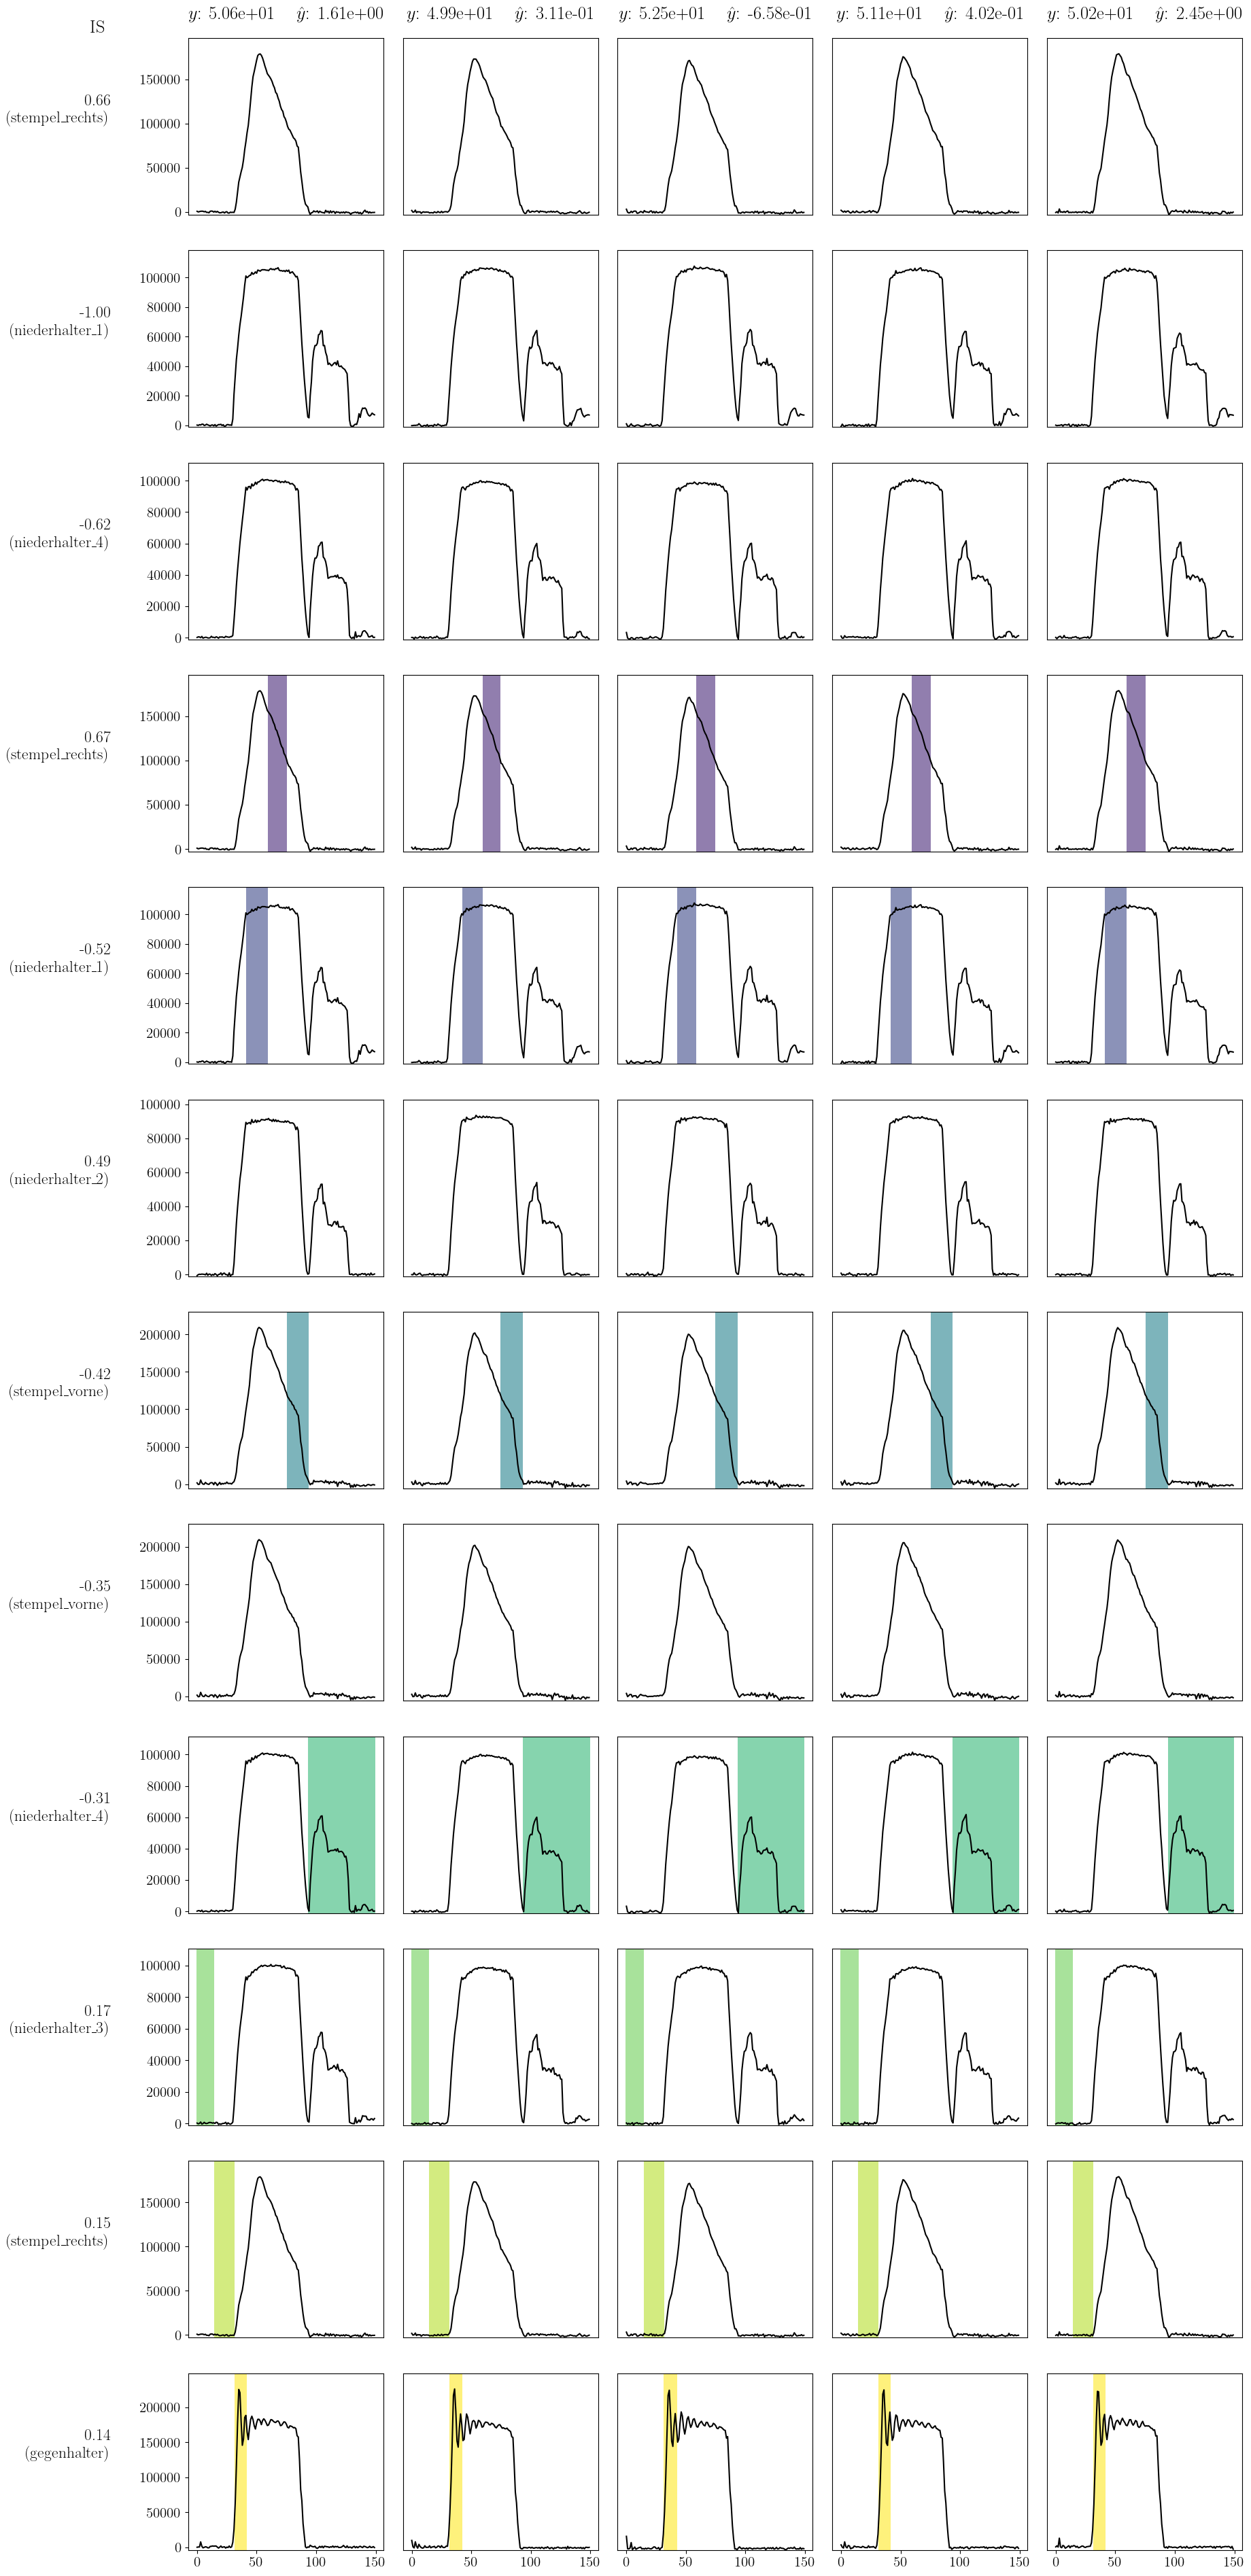

In [26]:
plot_concepts_report_from_HF(d1,CE.importances,cfg.dataset, rows=[i for i in range(5)])